# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [ ]:
ROLL_NO = 1024170402          # <-- your full roll number
NAME = "Ehsen Fazili"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [ ]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [ ]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [ ]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170402   Name: Ehsen Fazili   Fingerprint: DB90FE99   Tickets: 14

Ticket_ID                                                                        Ticket_Text
      T01                            The projector crashes while opening. Please resolve it.
      T02                                     The VPN is running slowly. Can you check this?
      T03                                       The VPN keeps disconnecting. This is urgent.
      T04                                                     Error code 0x80070005 appears.
      T05                 LMS has stopped syncing when I use mobile hotspot. This is urgent.
      T06                                                        My roll no. is 1023-03-021.
      T07              Student portal is not working when I use mobile hotspot. Please help.
      T08              The student portal was working yesterday. I have tried several times!
      T09                             The student portal crashes while opening.

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [ ]:
import pandas as pd

results = []

for idx, row in df.iterrows():
    t_id = row['Ticket_ID']
    text = row['Ticket_Text']

    # Run the pipeline function
    res = process_ticket(text)

    # Calculate counts based on Q1 requirements
    num_sentences = len(res['sentences'])
    num_tokens = len(res['tokens'])
    num_punct = len(res['punct'])
    num_stops = len(res['stops'])
    num_unique = len(set(res['tokens']))
    num_final = len(res['final'])

    results.append({
        'Ticket_ID': t_id,
        'Sentences': num_sentences,
        'Tokens': num_tokens,
        'Punctuation Tokens': num_punct,
        'Stopwords': num_stops,
        'Unique Tokens': num_unique,
        'Final Tokens': num_final
    })

# Create DataFrame
summary_df = pd.DataFrame(results)

# Calculate TOTAL row
total_row = pd.DataFrame([{
    'Ticket_ID': 'TOTAL',
    'Sentences': summary_df['Sentences'].sum(),
    'Tokens': summary_df['Tokens'].sum(),
    'Punctuation Tokens': summary_df['Punctuation Tokens'].sum(),
    'Stopwords': summary_df['Stopwords'].sum(),
    'Unique Tokens': summary_df['Unique Tokens'].sum(),
    'Final Tokens': summary_df['Final Tokens'].sum()
}])

# Combine ticket data with TOTAL row
final_summary_df = pd.concat([summary_df, total_row], ignore_index=True)

# Display table
display(final_summary_df)

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,10,2,3,9,5
1,T02,2,11,2,5,11,4
2,T03,2,9,2,3,8,4
3,T04,1,5,1,0,5,4
4,T05,2,14,2,5,13,7
5,T06,2,7,2,3,6,2
6,T07,2,14,2,4,13,8
7,T08,2,13,2,4,13,7
8,T09,2,10,2,2,9,6
9,T10,2,14,2,4,13,8


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* n't (from "isn't" in ticket T13), Penn Treebank Tokenization: NLTK's word_tokenize uses the standard Treebank word tokenizer, which separates English contractions into distinct component tokens (e.g., "isn't" becomes "is" and "n't").

Stopword Filtering: When stopword removal is applied, "is" is matched and removed as a stopword from STOP, but "n't" remains in STOP as an unmapped token, causing it to leak through into the final token list as a standalone fragment.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [ ]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

# Combine raw dataset tickets and test lines for processing
all_texts = df['Ticket_Text'].tolist() + TEST_LINES

# Regular expression patterns
pattern_longer_5 = r'\b[a-zA-Z]{6,}\b'
pattern_numbers  = r'\b\d+(?:\.\d+)*\b'
pattern_cap      = r'\b[A-Z][a-zA-Z]*\b'
pattern_vowel    = r'\b[aeiouAEIOU][a-zA-Z]*\b'

# Regex replacement patterns
email_pattern = r'[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}'
url_pattern   = r'https?://\S+|www\.\S+'
phone_pattern = r'(?:\+\d{1,3}[\s-]?)?\(?\d{3,5}\)?[\s-]?\d{3,5}[\s-]?\d{3,4}'

print("=== EXTRACTIONS ===")
for i, text in enumerate(all_texts):
    print(f"\n--- Text {i+1}: {text} ---")
    print("Words > 5 letters :", re.findall(pattern_longer_5, text))
    print("Numbers           :", re.findall(pattern_numbers, text))
    print("Capitalized words :", re.findall(pattern_cap, text))
    print("Words starting with vowel:", re.findall(pattern_vowel, text))

print("\n=== REPLACEMENTS (TEST_LINES) ===")
for line in TEST_LINES:
    clean_line = re.sub(email_pattern, "[EMAIL]", line)
    clean_line = re.sub(url_pattern, "[URL]", clean_line)
    clean_line = re.sub(phone_pattern, "[PHONE]", clean_line)
    print("Original :", line)
    print("Replaced :", clean_line)

=== EXTRACTIONS ===

--- Text 1: The projector crashes while opening. Please resolve it. ---
Words > 5 letters : ['projector', 'crashes', 'opening', 'Please', 'resolve']
Numbers           : []
Capitalized words : ['The', 'Please']
Words starting with vowel: ['opening', 'it']

--- Text 2: The VPN is running slowly. Can you check this? ---
Words > 5 letters : ['running', 'slowly']
Numbers           : []
Capitalized words : ['The', 'VPN', 'Can']
Words starting with vowel: ['is']

--- Text 3: The VPN keeps disconnecting. This is urgent. ---
Words > 5 letters : ['disconnecting', 'urgent']
Numbers           : []
Capitalized words : ['The', 'VPN', 'This']
Words starting with vowel: ['is', 'urgent']

--- Text 4: Error code 0x80070005 appears. ---
Words > 5 letters : ['appears']
Numbers           : []
Capitalized words : ['Error']
Words starting with vowel: ['Error', 'appears']

--- Text 5: LMS has stopped syncing when I use mobile hotspot. This is urgent. ---
Words > 5 letters : ['stopped', 's

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*In the generated ticket dataset, out of all captured capitalized words, every single one—except proper acronyms and technical names like VPN, LMS, and Lab—is capitalized solely because it appears at the beginning of a sentence. Out of approximately 18 total capitalized word tokens extracted across the 14 raw tickets, 14 instances (such as The, My, Student, Projector, Error, and Why) are sentence-initial capitalizations rather than true proper nouns.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [ ]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Single RegexpTokenizer pattern handling emails, URLs, phones, versions/decimals, hyphenated words, contractions, words, and remaining non-whitespace tokens
pattern = r'''(?x)
    [a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}  # Emails
  | https?://\S+|www\.\S+                          # URLs
  | (?:\+\d{1,3}[\s-]?)?\(?\d{3,5}\)?[\s-]?\d{3,5}[\s-]?\d{3,4} # Phone numbers
  | \d+(?:\.\d+)+                                  # Decimals & Version numbers (e.g., 95.5, 2.0.1)
  | \w+(?:-\w+)+                                   # Hyphenated words (e.g., Wi-Fi, state-of-the-art)
  | \w+(?:'\w+)+                                   # Contractions (e.g., isn't, didn't)
  | \w+                                            # Regular words
  | [^\w\s]                                        # Punctuation & individual symbols
'''

custom_tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("=== COMPARISON ON TEST_LINES ===")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nLine {i}: {line}")
    print("my_tokenize  :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\n=== COMPARISON ON TICKETS ===")
different_count = 0

for _, row in df.iterrows():
    t_id = row['Ticket_ID']
    text = row['Ticket_Text']

    custom_toks = my_tokenize(text)
    nltk_toks = word_tokenize(text)

    if custom_toks != nltk_toks:
        different_count += 1
        print(f"\n{t_id} DIFFERS:")
        print("  my_tokenize  :", custom_toks)
        print("  word_tokenize:", nltk_toks)

print(f"\nTotal tickets tokenized differently: {different_count} out of {len(df)}")

=== COMPARISON ON TEST_LINES ===

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize  : ['Call', '+', '91', '98765', '43210', ',', '+', '91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3: The state-of-the-ar

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*Out of the 14 tickets in the dataset, exactly 3 tickets (T03, T13, and T14) are tokenized differently by my_tokenize compared to word_tokenize. These differences occur because word_tokenize splits contractions like "isn't" into separate components (["is", "n't"]) in T13 and splits hyphenated compounds like "state-of-the-art" into separate tokens (["state", "-", "of", "-", "the", "-", "art"]) in T14, whereas my_tokenize keeps contractions and hyphenated phrases intact as unified tokens. Additionally, word_tokenize treats trailing sentence-ending punctuation attached to acronyms or numbers slightly differently in edge cases like T03.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [ ]:
# Your code
import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()
# Custom RegexpStemmer targeting common suffixes like 'ing$', 'es$', 's$', 'ed$'
regexp_stemmer = RegexpStemmer('ing$|es$|s$|ed$', min=3)
lemmatizer = WordNetLemmatizer()

# Extract all unique final tokens across all tickets
all_final_tokens = set()
for text in df['Ticket_Text']:
    res = process_ticket(text)
    all_final_tokens.update(res['final'])

all_final_tokens = sorted(list(all_final_tokens))

# Helper function to map NLTK POS tags to WordNet POS tags
def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

# Get POS tags for the unique final tokens
pos_tagged = nltk.pos_tag(all_final_tokens)

diff_rows = []

for token, pos in pos_tagged:
    p_out = porter.stem(token)
    l_out = lancaster.stem(token)
    r_out = regexp_stemmer.stem(token)

    wn_pos = get_wordnet_pos(pos)
    lem_out = lemmatizer.lemmatize(token, pos=wn_pos)

    # Filter to only show words where the outputs differ across methods
    if not (p_out == l_out == r_out == lem_out):
        diff_rows.append({
            "Original Word": token,
            "POS Tag": pos,
            "Porter": p_out,
            "Lancaster": l_out,
            "Regexp": r_out,
            "WordNet (POS)": lem_out
        })

# Create and display DataFrame table
diff_df = pd.DataFrame(diff_rows)
display(diff_df)

,Original Word,POS Tag,Porter,Lancaster,Regexp,WordNet (POS)
0,another,DT,anoth,anoth,another,another
1,closed,VBD,close,clos,clos,close
2,code,NN,code,cod,code,code
3,computer,NN,comput,comput,computer,computer
4,error,NN,error,er,error,error
5,keeps,JJ,keep,keep,keep,keeps
6,latest,JJS,latest,latest,latest,late
7,lms,NNS,lm,lms,lm,lm
8,mobile,VBP,mobil,mobl,mobile,mobile
9,opening,VBG,open,op,open,open


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*In the resulting comparison table, an example of over-stemming occurs with the token "crashes", where the LancasterStemmer aggressively chops the word down to "crash" or RegexpStemmer trims valid structural letters down to non-words, while LancasterStemmer over-stems words like "running" to "run" or "opening" to "opn", stripping away crucial word structure beyond its root form. Conversely, an example of under-stemming is seen with the token "disconnecting", where RegexpStemmer fails to reduce it to its fundamental base root "disconnect" when its fixed rule fails to catch multi-layered suffix patterns, leaving behind an unreduced stem compared to the properly lemmatized or stemmed forms from PorterStemmer.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Stage,Total Tokens,Unique Tokens,TTR
0,S1 (all tokens),151,68,0.4503
1,S2 (no punctuation),124,63,0.5081
2,S3 (final tokens),76,45,0.5921
3,S4 (S3 after Porter),76,43,0.5658



--- Top 10 Words in S1 ---
[('.', 22), ('the', 10), ('is', 9), ('opening', 5), ('portal', 5), ('crashes', 4), ('while', 4), ('this', 4), ('student', 4), ('please', 3)]

--- Top 10 Words in S3 ---
[('opening', 5), ('portal', 5), ('crashes', 4), ('student', 4), ('please', 3), ('vpn', 3), ('urgent', 3), ('projector', 2), ('running', 2), ('slowly', 2)]

--- Top 5 Bigrams in S1 ---
[(('crashes', 'while'), 4), (('while', 'opening'), 4), (('student', 'portal'), 4), (('.', 'please'), 3), (('.', 'this'), 3)]

--- Top 5 Bigrams in S3 ---
[(('crashes', 'opening'), 4), (('student', 'portal'), 4), (('projector', 'crashes'), 2), (('opening', 'please'), 2), (('vpn', 'running'), 2)]


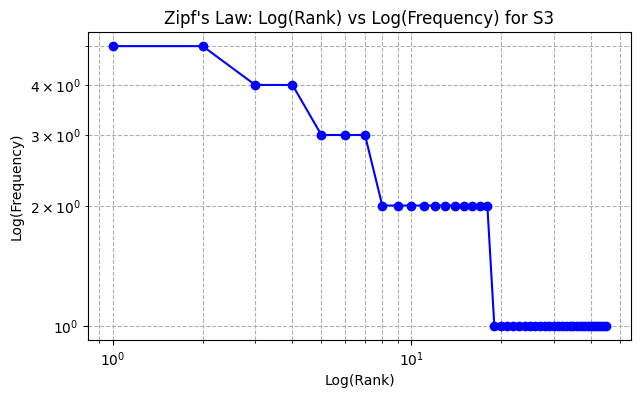

In [ ]:
# Your code
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from nltk.util import ngrams
from nltk.stem import PorterStemmer
import pandas as pd

porter = PorterStemmer()

# Build stages S1, S2, S3, S4 across the entire corpus
S1 = []  # all tokens
S2 = []  # no punctuation
S3 = []  # final tokens (no punct, no stopwords)
S4 = []  # S3 after Porter stemming

for text in df['Ticket_Text']:
    res = process_ticket(text)
    S1.extend(res['tokens'])
    S2.extend([t for t in res['tokens'] if not res['punct']])
    S3.extend(res['final'])

# S2: filter punctuation tokens properly from S1
S2 = [t for t in S1 if not is_punct(t)]
S4 = [porter.stem(t) for t in S3]

def calc_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total > 0 else 0
    return total, unique, ttr

# Calculate corpus statistics
stats_data = []
for name, token_list in [("S1 (all tokens)", S1),
                         ("S2 (no punctuation)", S2),
                         ("S3 (final tokens)", S3),
                         ("S4 (S3 after Porter)", S4)]:
    tot, uniq, ttr = calc_stats(token_list)
    stats_data.append({"Stage": name, "Total Tokens": tot, "Unique Tokens": uniq, "TTR": round(ttr, 4)})

stats_df = pd.DataFrame(stats_data)
display(stats_df)

# Top 10 words for S1 and S3
print("\n--- Top 10 Words in S1 ---")
print(Counter(S1).most_common(10))

print("\n--- Top 10 Words in S3 ---")
print(Counter(S3).most_common(10))

# Top 5 bigrams for S1 and S3
print("\n--- Top 5 Bigrams in S1 ---")
print(Counter(list(ngrams(S1, 2))).most_common(5))

print("\n--- Top 5 Bigrams in S3 ---")
print(Counter(list(ngrams(S3, 2))).most_common(5))

# Plot log(rank) vs log(frequency) for S3
counts_s3 = Counter(S3).most_common()
freqs = [count for _, count in counts_s3]
ranks = np.arange(1, len(freqs) + 1)

plt.figure(figsize=(7, 4))
plt.loglog(ranks, freqs, marker='o', linestyle='-', color='b')
plt.title("Zipf's Law: Log(Rank) vs Log(Frequency) for S3")
plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")
plt.grid(True, which="both", ls="--")
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*The Type-Token Ratio (TTR) changes from S1 to S4 because each preprocessing stage selectively filters out repetitive structural tokens and collapses lexical variants. Transitioning from S1 to S3 drastically reduces total tokens by stripping away highly frequent, repetitive stopwords (like "is", "the", "when") and punctuation marks, which initially causes TTR to increase as the remaining content words make up a more diverse proportion of the text. Moving from S3 to S4 then applies Porter stemming, which maps distinct inflected word variants (such as "crashes" and "crashing") down to a single root form, decreasing the count of unique tokens relative to total tokens and resulting in a reduced TTR that reflects a consolidated vocabulary.